In [19]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

import tenpy
import tenpy.linalg.np_conserved as npc




# LATTICE

### Uniform Square Spin Lattice




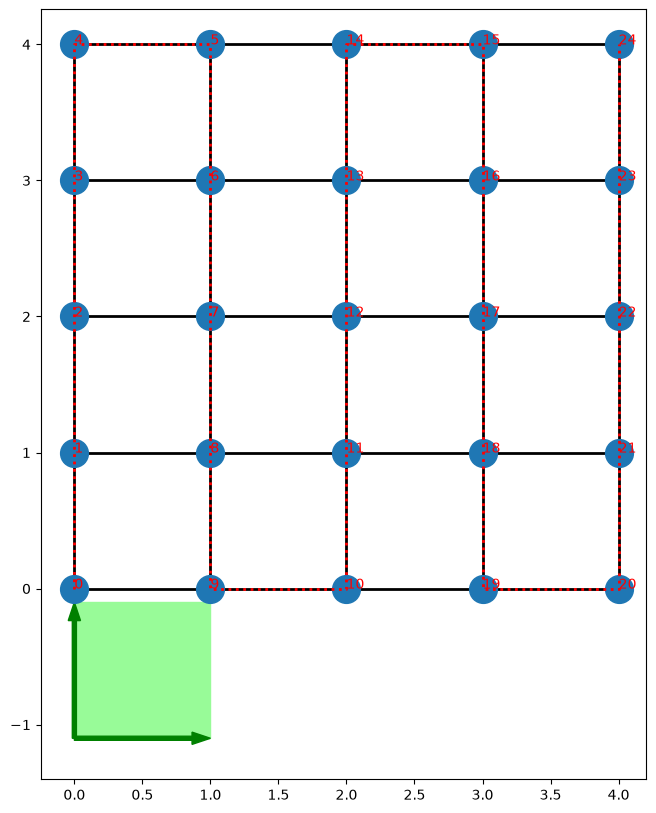

In [24]:
from tenpy.networks.site import BosonSite, SpinSite
from tenpy.models.lattice import Square

spin_site = SpinSite(S = 0.5, conserve=None)
lat = Square(5, 5, spin_site, order="snake")

plt.figure(figsize=(20, 10))
ax = plt.gca()
lat.plot_basis(ax, origin=(0, -1.1))
# ax.set_ylim(-1, 1)
# ax.set_xlim(-0.5, lat.Ls[0])
ax.set_aspect("equal")

# NN
lat.plot_coupling(ax, coupling=lat.pairs['nearest_neighbors'] ,lw=2)

# nNN
# lat.plot_coupling(ax, coupling=lat.pairs['next_nearest_neighbors'] ,color="orange", ls ="--", lw=1)

lat.plot_sites(ax, markersize=20)

# Order in which the sites are mapped to the MPS
lat.plot_order(ax, linestyle=":", color="r", lw=2)

### Our lattice: Spin coupled to an uniform Boson Chain

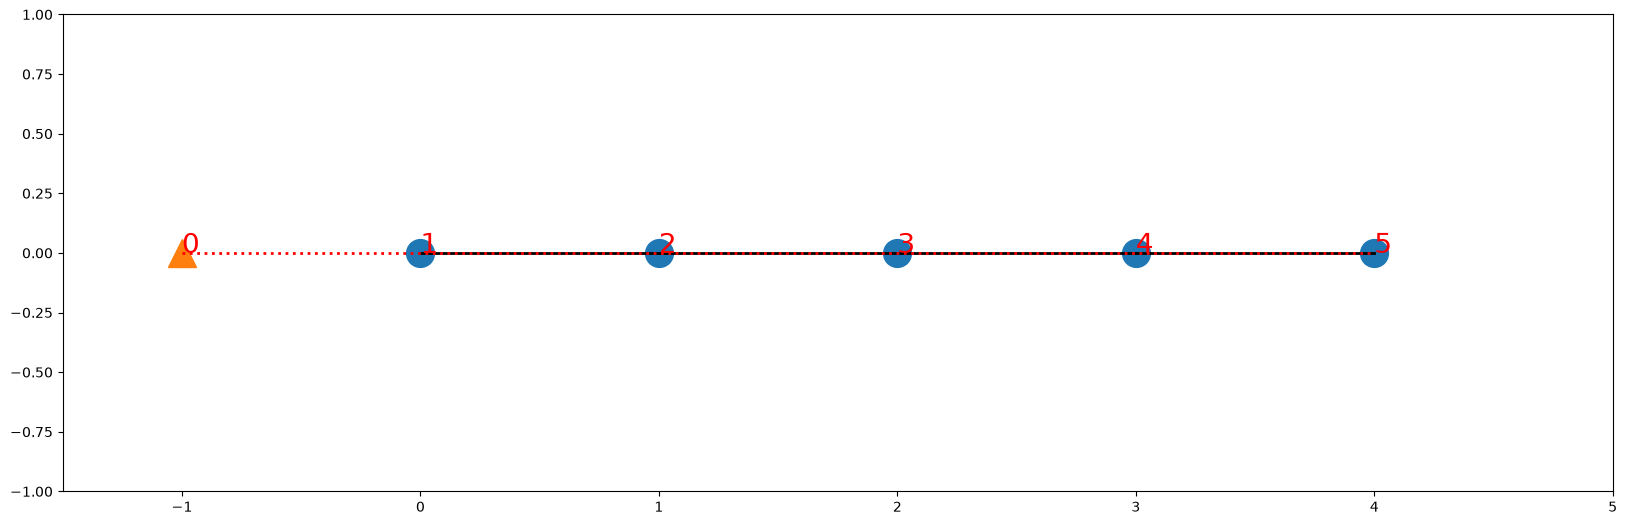

In [3]:
from tenpy.networks.site import BosonSite, SpinSite, set_common_charges
from tenpy.models.lattice import Chain, IrregularLattice, Lattice

boson_site = BosonSite(Nmax=2)
spin_site = SpinSite(S = 0.5, conserve=None)

# Uniform chain lattice of bosons
lat = Chain(5, boson_site)

# Add Spin-1/2 site to the chain lattice
set_common_charges([boson_site, spin_site], new_charges=[])
ilat = IrregularLattice(
    lat,
    add=([[0, 1]], [None]),
    add_unit_cell=[spin_site],
    add_positions=[np.array([-1])],
)
ilat.order = np.array([[[0, 1]] + list(lat.order)]).squeeze(0)

plt.figure(figsize=(20, 15))
ax = plt.gca()
ilat.plot_basis(ax, origin=(0, -1.1))
ilat.plot_sites(ax, markersize=20)
ilat.plot_coupling(ax, coupling=ilat.pairs['nearest_neighbors'] ,lw=2)
ax.set_ylim(-1, 1)
ax.set_xlim(-1.5, ilat.Ls[0])
ax.set_aspect("equal")
ilat.plot_order(ax, linestyle=":", color="r", lw=2, textkwargs={"fontsize": 20, "color": "r"})


In [4]:
ilat.mps_sites()

[SpinSite(S=0.5, 'None'),
 BosonSite(2, 'N', 0.000000),
 BosonSite(2, 'N', 0.000000),
 BosonSite(2, 'N', 0.000000),
 BosonSite(2, 'N', 0.000000),
 BosonSite(2, 'N', 0.000000)]

### MPS example

In [25]:
from tenpy.networks.mps import MPS

state = ["up", "vac", "vac", "vac", "vac", 1]
mps = MPS.from_product_state(ilat.mps_sites(), state)

mps._B[0].legs

/home/ihuarte/Escritorio/Ivan/MPS/.venv/lib/python3.12/site-packages/tenpy/networks/mps.py:1629: UserWarning: unit_cell_width is a new argument for MPS and similar classes. It is optional for now, but will become mandatory in a future release. The default value (unit_cell_width=len(sites)) is correct, iff the lattice is a Chain. For other lattices, it is incorrect. It is used for dipolar charges and correlation_function2.
  super().__init__(sites, bc, unit_cell_width)


[LegCharge(ChargeInfo([], []), qconj=+1,
 array([0, 1]), array([], shape=(1, 0), dtype=int64)),
 LegCharge(ChargeInfo([], []), qconj=+1,
 array([0, 2]), array([], shape=(1, 0), dtype=int64)),
 LegCharge(ChargeInfo([], []), qconj=-1,
 array([0, 1]), array([], shape=(1, 0), dtype=int64))]

In [26]:
print(f"Spin: \n{mps._B[0]}")
print(f"\n")
print(f"Cavity 0: \n{mps._B[1]}")


Spin: 
<npc.Array shape=(1, 2, 1) labels=['vL', 'p', 'vR']
charge=ChargeInfo([], [])
 +1 | +1 | -1 
0 []|0 []|0 []
1   |2   |1   
[[[0.]
  [1.]]]
>


Cavity 0: 
<npc.Array shape=(1, 3, 1) labels=['vL', 'p', 'vR']
charge=ChargeInfo([], [])
 +1 | +1 | -1 
0 []|0 []|0 []
1   |3   |1   
[[[1.]
  [0.]
  [0.]]]
>


# Hamiltonian

We can now build the MPO hamiltonian from the lattice by creating a CouplingModel instance where all the interactions are established via the operators defined in each site. 
- Spin: $S_x$, $S_y$, $S_z$, $\sigma^+$, $\sigma^-$, ....
- Bosons: N, $b^\dagger$ (creation), $b$ (destruction), ...


$$ H = \Delta S_z  + \omega_0 \sum_i b^\dagger_i b_i + J \sum_i (b_i b^\dagger_{i+1} + h.c.) + \frac{g_0}{2} (\sigma^+b_0 + h.c.)$$

In [7]:
from tenpy.models.model import CouplingModel

CM = CouplingModel(ilat)

delta = 0.3
w0 = 1.0
J = 0.5
g0 = 1.4 

In [27]:
# Spin energy term (onsite) (strength, site, operator)
CM.add_local_term(delta, [("Sz", [0, 1])])

# Cavity energy term (onsite) (strength, site, operator)
for i in range(0, ilat.N_sites-1):
    CM.add_local_term(w0, [("N", [i, 0])])

# Tight-binding term (hopping) 
for i in range(0, ilat.N_sites-2):
    CM.add_local_term(
        J, 
        [("B", [i, 0]), ("Bd", [i + 1, 0])], 
        plus_hc=True
    )

# Spin - cavity interaction term
CM.add_local_term(
    g0, 
    [("B", [0, 0]), ("Sp", [0, 1])], 
    plus_hc=True
)


In this manner all the hamiltonian terms are added and the H_MPO ready to build

In [9]:
print('Onsite Terms: \n\n ', CM.all_onsite_terms().to_TermList(),'\n\n')
print('Coupling Terms: \n\n ', CM.all_coupling_terms().to_TermList(),'\n\n')

Onsite Terms: 

  0.30000 * Sz_0 +
1.00000 * N_1 +
1.00000 * N_2 +
1.00000 * N_3 +
1.00000 * N_4 +
1.00000 * N_5 


Coupling Terms: 

  1.40000 * Sm_0 Bd_1 +
1.40000 * Sp_0 B_1 +
0.50000 * B_1 Bd_2 +
0.50000 * Bd_1 B_2 +
0.50000 * B_2 Bd_3 +
0.50000 * Bd_2 B_3 +
0.50000 * B_3 Bd_4 +
0.50000 * Bd_3 B_4 +
0.50000 * B_4 Bd_5 +
0.50000 * Bd_4 B_5 




In [10]:
H_MPO = CM.calc_H_MPO(tol_zero=1e-10)
H_MPO._W

[<npc.Array shape=(2, 4, 2, 2) labels=['wL', 'wR', 'p', 'p*']>,
 <npc.Array shape=(4, 4, 3, 3) labels=['wL', 'wR', 'p', 'p*']>,
 <npc.Array shape=(4, 4, 3, 3) labels=['wL', 'wR', 'p', 'p*']>,
 <npc.Array shape=(4, 4, 3, 3) labels=['wL', 'wR', 'p', 'p*']>,
 <npc.Array shape=(4, 4, 3, 3) labels=['wL', 'wR', 'p', 'p*']>,
 <npc.Array shape=(4, 2, 3, 3) labels=['wL', 'wR', 'p', 'p*']>]

In [11]:
H_MPO._W[1].to_ndarray()


array([[[[1.        , 0.        , 0.        ],
         [0.        , 1.        , 0.        ],
         [0.        , 0.        , 1.        ]],

        [[0.        , 1.        , 0.        ],
         [0.        , 0.        , 1.41421356],
         [0.        , 0.        , 0.        ]],

        [[0.        , 0.        , 0.        ],
         [1.        , 0.        , 0.        ],
         [0.        , 1.41421356, 0.        ]],

        [[0.        , 0.        , 0.        ],
         [0.        , 1.        , 0.        ],
         [0.        , 0.        , 2.        ]]],


       [[[0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ]],

        [[0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ]],

        [[0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ]]

# DMRG 

In [12]:
from tenpy.algorithms.dmrg import TwoSiteDMRGEngine

DMRG_options = {
    "min_sweeps":10,
    "max_sweeps":50,
    "trunc_params": {
        "chi_max": 100, 
        "svd_min": 1e-12
    }
}

In [13]:
state = ["up", "vac", "vac", "vac", "vac", 1]
initial_state = MPS.from_product_state(ilat.mps_sites(), state)
CM.H_MPO = CM.calc_H_MPO(tol_zero=1e-10)

/home/ihuarte/Escritorio/Ivan/MPS/.venv/lib/python3.12/site-packages/tenpy/networks/mps.py:1629: UserWarning: unit_cell_width is a new argument for MPS and similar classes. It is optional for now, but will become mandatory in a future release. The default value (unit_cell_width=len(sites)) is correct, iff the lattice is a Chain. For other lattices, it is incorrect. It is used for dipolar charges and correlation_function2.
  super().__init__(sites, bc, unit_cell_width)


In [14]:
eng = TwoSiteDMRGEngine(initial_state, CM, DMRG_options)
E_gr, psi_gr = eng.run()

In [15]:
psi_gr._B

[<npc.Array shape=(1, 2, 2) labels=['vL', 'p', 'vR']>,
 <npc.Array shape=(2, 3, 4) labels=['vL', 'p', 'vR']>,
 <npc.Array shape=(4, 3, 5) labels=['vL', 'p', 'vR']>,
 <npc.Array shape=(5, 3, 4) labels=['vL', 'p', 'vR']>,
 <npc.Array shape=(4, 3, 3) labels=['vL', 'p', 'vR']>,
 <npc.Array shape=(3, 3, 1) labels=['vL', 'p', 'vR']>]

# TEBD

In [16]:
from tenpy.algorithms.tebd import TEBDEngine

TEBD_options = {
    "N_steps": 1,
    "dt": 0.0001,
    "order": 4,
    "trunc_params": {"chi_max": 100, "svd_min": 1e-12},
    "Tmax": 0.1025,
    "preserve_norm": True
}
CM.H_bond = CM.calc_H_bond(tol_zero=1e-10)

In [17]:
eng_TEBD = TEBDEngine(initial_state, CM, TEBD_options)


In [18]:
Tmax = TEBD_options["Tmax"]

eng_TEBD.run()
psi_tmp = eng_TEBD.psi

psi_tmp._B

[<npc.Array shape=(1, 2, 2) labels=['vL', 'p', 'vR']>,
 <npc.Array shape=(2, 3, 4) labels=['vL', 'p', 'vR']>,
 <npc.Array shape=(4, 3, 5) labels=['vL', 'p', 'vR']>,
 <npc.Array shape=(5, 3, 4) labels=['vL', 'p', 'vR']>,
 <npc.Array shape=(4, 3, 3) labels=['vL', 'p', 'vR']>,
 <npc.Array shape=(3, 3, 1) labels=['vL', 'p', 'vR']>]